In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
with open('SMSSpamCollection' , 'r') as file :
    content = file.read()
    # print(content)

In [3]:
content.split('\n')[0]

'ham\tGo until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...'

In [4]:
content.split('\n')[0].split('\t')[0]

'ham'

In [5]:
Target = []
message = []
for i in content.split('\n'): 
    if '\t' in i :
        Target.append(i.split('\t')[0])
        message.append(i.split('\t')[1])

In [6]:
len(Target)

5574

In [7]:
len(message)

5574

In [8]:
df = pd.read_csv('spam1.csv')
df.head()

,Unnamed: 0,Messages,Result
0,0,"Go until jurong point, crazy.. Available only ...",ham
1,1,Ok lar... Joking wif u oni...,ham
2,2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,3,U dun say so early hor... U c already then say...,ham
4,4,"Nah I don't think he goes to usf, he lives aro...",ham


In [9]:
df = df.drop(columns = 'Unnamed: 0')

In [10]:
df.head()

,Messages,Result
0,"Go until jurong point, crazy.. Available only ...",ham
1,Ok lar... Joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,spam
3,U dun say so early hor... U c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...",ham


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Messages  5574 non-null   object
 1   Result    5574 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [12]:
df.isna()

,Messages,Result
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
5569,False,False
5570,False,False
5571,False,False
5572,False,False


In [13]:
X = df[['Messages']]
y = df['Result']

In [14]:
X.head()

,Messages
0,"Go until jurong point, crazy.. Available only ..."
1,Ok lar... Joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...
3,U dun say so early hor... U c already then say...
4,"Nah I don't think he goes to usf, he lives aro..."


In [15]:
X.iloc[0]

Messages    Go until jurong point, crazy.. Available only ...
Name: 0, dtype: object

In [16]:
import string

In [17]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [18]:
def remove_punc(text):
    result = ''
    for i in text:
        if i not in string.punctuation:
            result += i
    return result

In [19]:
txt = 'Go @!until jurong point, crazy.. Available only ...'

In [20]:
remove_punc(txt)

'Go until jurong point crazy Available only '

In [21]:
X['Messages'].apply(remove_punc)

0       Go until jurong point crazy Available only in ...
1                                 Ok lar Joking wif u oni
2       Free entry in 2 a wkly comp to win FA Cup fina...
3             U dun say so early hor U c already then say
4       Nah I dont think he goes to usf he lives aroun...
                              ...                        
5569    This is the 2nd time we have tried 2 contact u...
5570                 Will Ã¼ b going to esplanade fr home
5571    Pity  was in mood for that Soany other suggest...
5572    The guy did some bitching but I acted like id ...
5573                            Rofl Its true to its name
Name: Messages, Length: 5574, dtype: object

In [22]:
X['Messages'] = X['Messages'].apply(remove_punc)

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\1238379343.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(remove_punc)


In [23]:
X['Messages'] = X['Messages'].str.lower()

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\2801631647.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].str.lower()


In [24]:
X['Messages']

0       go until jurong point crazy available only in ...
1                                 ok lar joking wif u oni
2       free entry in 2 a wkly comp to win fa cup fina...
3             u dun say so early hor u c already then say
4       nah i dont think he goes to usf he lives aroun...
                              ...                        
5569    this is the 2nd time we have tried 2 contact u...
5570                 will ã¼ b going to esplanade fr home
5571    pity  was in mood for that soany other suggest...
5572    the guy did some bitching but i acted like id ...
5573                            rofl its true to its name
Name: Messages, Length: 5574, dtype: object

## Tokenization

In [25]:
X['Messages'].str.split()

0       [go, until, jurong, point, crazy, available, o...
1                          [ok, lar, joking, wif, u, oni]
2       [free, entry, in, 2, a, wkly, comp, to, win, f...
3       [u, dun, say, so, early, hor, u, c, already, t...
4       [nah, i, dont, think, he, goes, to, usf, he, l...
                              ...                        
5569    [this, is, the, 2nd, time, we, have, tried, 2,...
5570        [will, ã¼, b, going, to, esplanade, fr, home]
5571    [pity, was, in, mood, for, that, soany, other,...
5572    [the, guy, did, some, bitching, but, i, acted,...
5573                     [rofl, its, true, to, its, name]
Name: Messages, Length: 5574, dtype: object

In [26]:
from nltk.tokenize import word_tokenize

In [27]:
# split --- > no meningfull tokenization happen
# word_tokenize ---> meanubngful tokenization happen

In [28]:
X['Messages'] = X['Messages'].apply(word_tokenize)

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\1629355499.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(word_tokenize)


In [29]:
# lst = X['Messages'].iloc[2]

In [30]:
# [i for i in lst if not i.isdigit()]

In [31]:
def remove_digit(txt):
    new_ls = []
    for i in txt:
        if i.isalpha():
            new_ls.append(i)
    return new_ls

In [32]:
X['Messages'] = X['Messages'].apply(remove_digit)

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\3883038210.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(remove_digit)


In [33]:
X['Messages']

0       [go, until, jurong, point, crazy, available, o...
1                          [ok, lar, joking, wif, u, oni]
2       [free, entry, in, a, wkly, comp, to, win, fa, ...
3       [u, dun, say, so, early, hor, u, c, already, t...
4       [nah, i, dont, think, he, goes, to, usf, he, l...
                              ...                        
5569    [this, is, the, time, we, have, tried, contact...
5570            [will, b, going, to, esplanade, fr, home]
5571    [pity, was, in, mood, for, that, soany, other,...
5572    [the, guy, did, some, bitching, but, i, acted,...
5573                     [rofl, its, true, to, its, name]
Name: Messages, Length: 5574, dtype: object

In [34]:
# corpuss -- >> collection of documentss

In [35]:
from nltk.corpus import stopwords

In [36]:
stopwords.words('english')

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [37]:
len(stopwords.words('english'))

198

In [38]:
len(set(stopwords.words('english')))

198

In [39]:
lst = ['go', 'until', 'jurong', 'point', 'crazy', 'available', 'only', 'in', 'bugis', 'n', 'great', 'world', 'la', 'e', 'buffet', 'cine', 'there', 'got', 'amore', 'wat']

In [40]:
stop_words = set(stopwords.words('english'))
def remove_stop(txt):
    new_txt = []
    for i in txt:
        if i not in stop_words:
            new_txt.append(i)
    return new_txt

In [41]:
X['Messages'] = X['Messages'].apply(remove_stop)

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\4155903069.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(remove_stop)


In [42]:
X['Messages']

0       [go, jurong, point, crazy, available, bugis, n...
1                          [ok, lar, joking, wif, u, oni]
2       [free, entry, wkly, comp, win, fa, cup, final,...
3           [u, dun, say, early, hor, u, c, already, say]
4       [nah, dont, think, goes, usf, lives, around, t...
                              ...                        
5569    [time, tried, contact, u, u, pound, prize, cla...
5570                      [b, going, esplanade, fr, home]
5571                     [pity, mood, soany, suggestions]
5572    [guy, bitching, acted, like, id, interested, b...
5573                                   [rofl, true, name]
Name: Messages, Length: 5574, dtype: object

In [43]:
from nltk.stem import PorterStemmer , WordNetLemmatizer

In [44]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\saksh\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [45]:
stem = PorterStemmer()

In [46]:
lemmitizer = WordNetLemmatizer()

In [47]:
stem.stem('running')

'run'

In [48]:
stem.stem('congratulation')

'congratul'

In [49]:
stem.stem('studying')

'studi'

In [50]:
lemmitizer.lemmatize('studying' , pos='v')

'study'

In [51]:
# def lem(words):
#     return [lemmitizer.lemmatize(w, pos='v') for w in words]

# X['Messages'] = X['Messages'].apply(lem)

In [52]:
def lem(word):
    new_word = []
    for i in word:
        new_word.append(lemmitizer.lemmatize(i, pos='v'))
    return new_word

X['Messages'] = X['Messages'].apply(lem)

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\3865146232.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(lem)


In [53]:
from sklearn.feature_extraction.text import CountVectorizer

In [54]:
cv = CountVectorizer()
cv

,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None
,"stop_words stop_words: {'english'}, list, default=NoneIf 'english', a built-in stop word list for English is used.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",None
,"token_pattern token_pattern: str or None, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp select tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'(?u)\\b\\w\\w+\\b'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentword n-grams or char n-grams to be extracted. All values of n suchsuch that min_n <= n <= max_n will be used. For example an``ngram_range`` of ``(1, 1)`` means only unigrams, ``(1, 2)`` meansunigrams and bigrams, and ``(2, 2)`` means only bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word n-gram or charactern-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21Since v0.21, if ``input`` is ``filename`` or ``file``, the data isfirst read from the file and then passed to the given callableanalyzer.",'word'


In [55]:
X['Messages'] = X['Messages'].apply(lambda x: " ".join(x))

C:\Users\saksh\AppData\Local\Temp\ipykernel_25832\2428808913.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Messages'] = X['Messages'].apply(lambda x: " ".join(x))


In [56]:
X['Messages']

0       go jurong point crazy available bugis n great ...
1                                   ok lar joke wif u oni
2       free entry wkly comp win fa cup final tkts may...
3                     u dun say early hor u c already say
4                nah dont think go usf live around though
                              ...                        
5569    time try contact u u pound prize claim easy ca...
5570                               b go esplanade fr home
5571                          pity mood soany suggestions
5572    guy bitch act like id interest buy something e...
5573                                       rofl true name
Name: Messages, Length: 5574, dtype: object

In [57]:
com_data = cv.fit_transform(X['Messages'])

In [58]:
com_data

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 44322 stored elements and shape (5574, 7205)>

In [59]:
new_X = com_data.toarray()
new_X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(5574, 7205))

In [60]:
from sklearn.linear_model import LogisticRegression

In [61]:
lr = LogisticRegression(max_iter=1000)

In [62]:
lr.fit(new_X , y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [63]:
y_pred = lr.predict(new_X)

In [64]:
from sklearn.metrics import accuracy_score , confusion_matrix , classification_report

In [65]:
accuracy_score(y , y_pred)

0.9947972730534625

In [66]:
print(classification_report(y , y_pred))

              precision    recall  f1-score   support

         ham       0.99      1.00      1.00      4827
        spam       1.00      0.96      0.98       747

    accuracy                           0.99      5574
   macro avg       1.00      0.98      0.99      5574
weighted avg       0.99      0.99      0.99      5574



In [67]:
confusion_matrix(y , y_pred)

array([[4826,    1],
       [  28,  719]])

<Axes: >

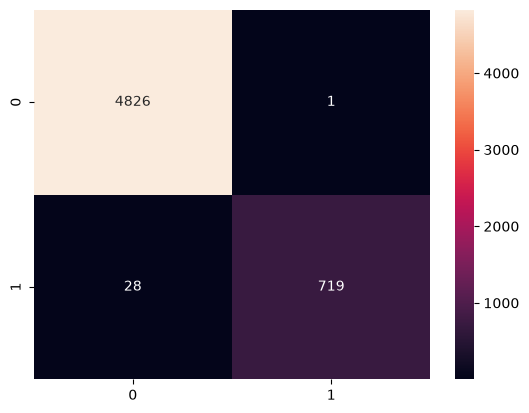

In [68]:
sns.heatmap(confusion_matrix(y , y_pred) , annot = True , fmt = 'd')

In [69]:
from sklearn.model_selection import cross_val_score

In [70]:

def Predict(msg):
    msg = remove_punc(msg)
    msg = msg.lower()
    tokens = word_tokenize(msg)
    tokens = remove_digit(tokens)
    tokens = remove_stop(tokens)
    tokens = lem(tokens)
    text = " ".join(tokens)

    vec = cv.transform([text])
    return lr.predict(vec)[0]

In [71]:
Predict("Congratulations! You won a free prize, call now")

'spam'

In [72]:
Predict("hey, are we meeting at 5?") 

'ham'

In [73]:
import pickle

with open('cv.pkl', 'wb') as f:
    pickle.dump(cv, f)

with open('lr.pkl', 'wb') as f:
    pickle.dump(lr, f)